In [107]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

from dtreeviz import model
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [108]:
iris = load_iris()
data = iris.data
target = iris.target


df1 = pd.DataFrame(data, columns= iris.feature_names)

df = pd.DataFrame(data, columns= iris.feature_names)
df['specie'] = target

df = df.sample(frac = 1, random_state = 1).reset_index(drop = True)
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),specie
0,5.8,4.0,1.2,0.2,0
1,5.1,2.5,3.0,1.1,1
2,6.6,3.0,4.4,1.4,1
3,5.4,3.9,1.3,0.4,0
4,7.9,3.8,6.4,2.0,2
...,...,...,...,...,...
145,6.3,2.8,5.1,1.5,2
146,6.4,3.1,5.5,1.8,2
147,6.3,2.5,4.9,1.5,1
148,6.7,3.1,5.6,2.4,2


In [109]:
rename_cols = {'sepal width (cm)': 'sepal_width',
               'petal length (cm)': 'petal_length'
               }

df.rename(columns= rename_cols, inplace = True)

df.head()

,sepal length (cm),sepal_width,petal_length,petal width (cm),specie
0,5.8,4.0,1.2,0.2,0
1,5.1,2.5,3.0,1.1,1
2,6.6,3.0,4.4,1.4,1
3,5.4,3.9,1.3,0.4,0
4,7.9,3.8,6.4,2.0,2


In [110]:
# For ease in understanding, we will consider only two columns.
# sepal_width and petal_length

# Also, we will take rows of specie = 1 and 2

df = df[df['specie'] != 0] [["sepal_width", 'petal_length', "specie"]].reset_index(drop = True)

df

,sepal_width,petal_length,specie
0,2.5,3.0,1
1,3.0,4.4,1
2,3.8,6.4,2
3,3.3,4.7,1
4,3.1,5.1,2
...,...,...,...
95,2.6,3.5,1
96,2.8,5.1,2
97,3.1,5.5,2
98,2.5,4.9,1


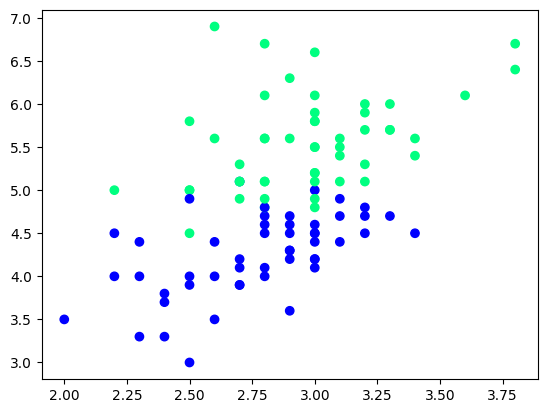

In [111]:
plt.scatter(df['sepal_width'], df['petal_length'], c = df['specie'], cmap = 'winter')

In [112]:
# Taking only 20 rows for training

df_train = df.iloc[0:60].sample(20)
df_val = df.iloc[60:80].sample(10)
df_test = df.iloc[80:].sample(10)

print(f"""Train size:{df_train.shape}
Validation size: {df_val.shape}
Test size: {df_test.shape}""")

Train size:(20, 3)
Validation size: (10, 3)
Test size: (10, 3)


In [113]:
# Seperate label from validation

x_test = df_val.iloc[:, 0:2]
y_test = df_val.iloc[:, -1]

x_test

,sepal_width,petal_length
65,2.3,4.4
78,3.0,5.2
64,3.0,5.2
73,3.4,5.6
77,2.7,5.1
69,2.7,3.9
62,2.9,4.3
79,2.5,4.5
74,2.8,4.9
71,3.1,4.9


In [114]:
print(x_test.columns)
print(iris.target_names)
print(y_test.unique())

Index(['sepal_width', 'petal_length'], dtype='object')
['setosa' 'versicolor' 'virginica']
[1 2]


In [115]:
def evaluate(clf, x, y):
    clf.fit(x, y)
    # viz = model(
    #     model = clf,
    #     X_train = x,
    #     y_train = y,
    #     feature_names = x.columns,
    #     class_names = ['versicolor', 'verginica'],
    #     #target_name = 'specie'
    # )

    # viz.view()

    plot_tree((clf))
    plt.show()
    plot_decision_regions(x.values, y.values, clf = clf, legend = 2)
    y_pred = clf.predict(x_test)
    print(accuracy_score(y_test, y_pred))

# Bagging Starts

In [116]:
# Data for tree 1. We will consider only 16 rows in training
df_bag = df_train.sample(16, replace = True).reset_index(drop = True)

# Seperating x and y

x = df.iloc[:, 0:2]
y = df.iloc[:, -1]

df_bag

,sepal_width,petal_length,specie
0,3.3,5.7,2
1,3.0,4.9,2
2,2.8,5.6,2
3,2.8,4.1,1
4,3.8,6.4,2
5,2.8,6.7,2
6,2.8,5.6,2
7,2.5,5.0,2
8,3.8,6.4,2
9,3.1,4.4,1


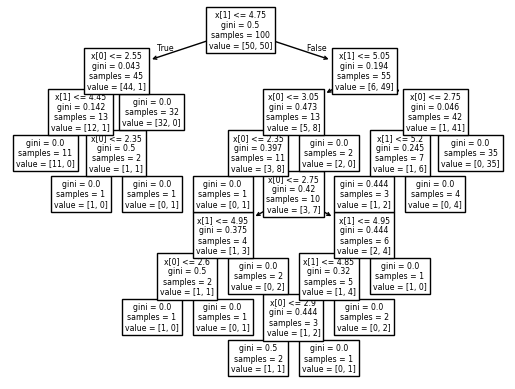

1.0


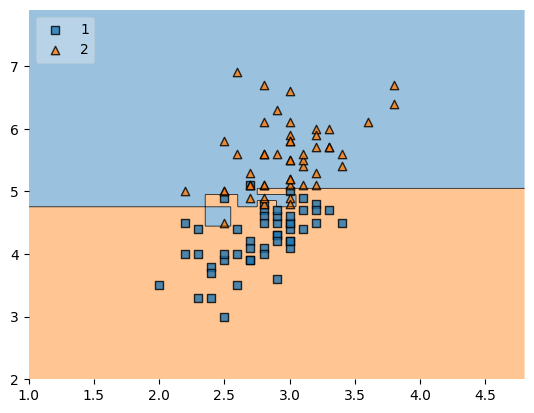

In [117]:
dt_1 = DecisionTreeClassifier()    # Training the whole decision tree

evaluate(clf = dt_1, x = x, y = y)

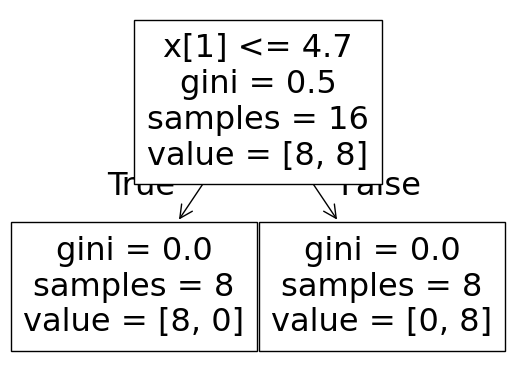

0.8


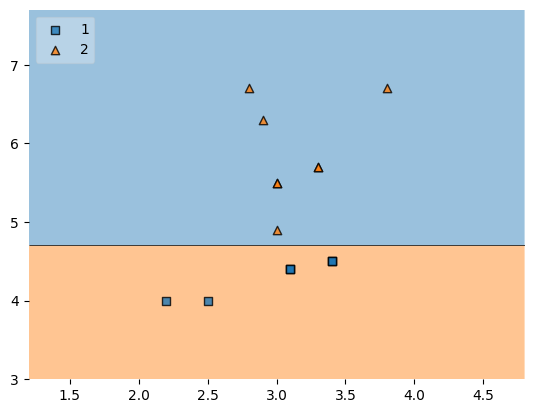

In [118]:
# Train DT2 on other subset of data

df_bag = df_train.sample(16, replace = True).reset_index(drop = True)

x = df_bag.iloc[:, 0:2]
y = df_bag.iloc[:, -1]


dt_2 = DecisionTreeClassifier()

evaluate(clf = dt_2, x = x, y = y)

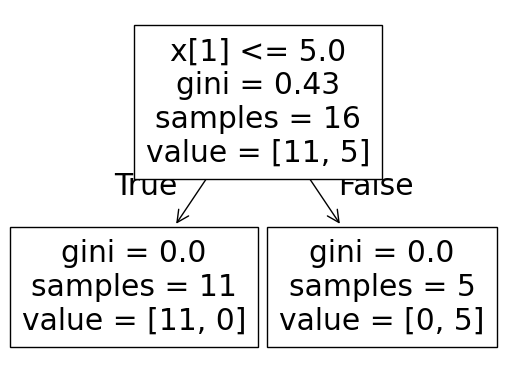

0.8


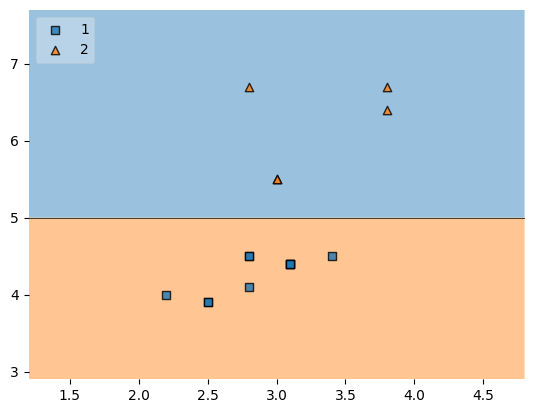

In [119]:
# Train DT3 on other subset of data

df_bag = df_train.sample(16, replace = True).reset_index(drop = True)

x = df_bag.iloc[:, 0:2]
y = df_bag.iloc[:, -1]


dt_3 = DecisionTreeClassifier()

evaluate(clf = dt_3, x = x, y = y)

# Prediction

In [120]:
import numpy as np
import warnings
warnings.filterwarnings("ignore")

In [121]:
df_test

,sepal_width,petal_length,specie
93,2.8,4.0,1
92,2.6,5.6,2
87,3.1,4.7,1
81,3.0,4.1,1
95,2.6,3.5,1
98,2.5,4.9,1
96,2.8,5.1,2
94,3.0,5.8,2
86,2.9,4.7,1
85,3.0,4.2,1


In [122]:
print(f"""Decision Tree 1: {dt_1.predict(np.array([[3.1, 5.6]]))}
Decision Tree 2: {dt_2.predict(np.array([[3.1, 5.6]]))}
Decision Tree 3: {dt_3.predict(np.array([[3.1, 5.6]]))}""")

Decision Tree 1: [2]
Decision Tree 2: [2]
Decision Tree 3: [2]


# Types of Sampling
- In bagging, we did sampling with replacement.
- But there are some other methods for sampling as well.

1) `Pasting`: Everything is same, the only difference is, here we take sample without replacement.
2) `Random Subspaces`: Here, we only do column sampling(With or without replacement), we dont do row sampling here.
3) `Random Patches`: Here we perform both, row sampling and column sampling

In [130]:
# Pasting: Row sampling without sampling
df_train.sample(12)

,sepal_width,petal_length,specie
47,2.8,4.5,1
39,2.8,6.7,2
20,3.0,6.1,2
46,3.1,4.4,1
38,3.4,4.5,1
35,2.9,6.3,2
44,3.0,4.9,2
58,2.7,5.3,2
48,3.3,5.7,2
21,2.5,3.9,1


In [ ]:
# Random Subspace: Only column sampling (With or without replacement)

df1.sample(2, replace = True, axis = 'columns')
# We will need to add specie seperately after sampling

,petal length (cm),sepal length (cm)
0,1.4,5.1
1,1.4,4.9
2,1.3,4.7
3,1.5,4.6
4,1.4,5.0
...,...,...
145,5.2,6.7
146,5.0,6.3
147,5.2,6.5
148,5.4,6.2


In [ ]:
# Random Patches: Here we perform both, row sampling and column sampling.

df1.sample(20, replace = True).sample(2, replace = True, axis = 'columns').reset_index(drop = True)
# We will need to add specie seperately after sampling


,sepal width (cm),petal width (cm)
0,3.9,0.4
1,3.9,0.4
2,2.8,2.0
3,3.1,0.2
4,3.0,1.8
5,2.2,1.5
6,3.1,0.2
7,2.8,2.1
8,2.6,1.2
9,3.3,0.5


# Session Complete

# Next Session: We will apply these other sampling techniques and see what changes happens in the results.